# Notebook 2: Data cleaning, missing values and outliers (onion and maize)

**Input:** `data/focus_crops_raw.csv` (made by Notebook 1)
**Outputs:**
- `data/focus_crops_clean.csv`: every cleaned price record, with flags showing what was changed
- `data/weekly_panel.csv`: one price per market per week, the table used for EDA, models and simulation
- `data/cleaning_log.csv`: how many rows each step touched (for the report)

**Steps**
1. Load and standardise types and text
2. Choose the study period
3. Validate prices against rules (invalid values)
4. Duplicates and conflicting records
5. Inconsistent categories (varieties and grades)
6. Outliers: detect, separate data-entry errors from real price spikes, treat, compare before and after
7. Missing values: diagnose the pattern, compare five filling methods, apply the best one
8. Before/after summary and save

**Not done here, on purpose:** scaling and categorical encoding. They are fitted on the training data only, in the
modelling notebook, so that no information from the test period leaks into the model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RAW_FILE = "../data/focus_crops_raw.csv"
SEED = 42

BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CROP_COLOR = {"Maize": BLUE, "Onion": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
})
pd.set_option("display.width", 160)

log = []   # cleaning log: one row per step
def record(step, detail, rows_affected, rows_after):
    log.append({"step": step, "detail": detail, "rows_affected": int(rows_affected), "rows_after": int(rows_after)})
    print(f"[{step}] {detail}: {int(rows_affected):,} rows affected -> {int(rows_after):,} rows")

## 1. Load and standardise types and text

In [2]:
raw = pd.read_csv(RAW_FILE)
print(f"Raw rows: {len(raw):,}")
print(raw.dtypes)

df = raw.copy()
df.columns = [c.lower() for c in df.columns]            # snake_case names: state, district, market, ...
df = df.rename(columns={"arrival_date": "date"})

text_cols = ["state", "district", "market", "commodity", "variety", "grade"]
for c in text_cols:
    df[c] = df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)   # trim, collapse spaces

df["date"] = pd.to_datetime(df["date"], errors="coerce")
for c in ["min_price", "max_price", "modal_price"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["commodity_code"] = pd.to_numeric(df["commodity_code"], errors="coerce").astype("Int64")

print("\nAfter type conversion:")
print(df.dtypes)
print("Unreadable dates:", df["date"].isna().sum(), "| unreadable prices:", df[["min_price","max_price","modal_price"]].isna().sum().sum())
record("1 Types", "Converted text, dates and prices to proper types", 0, len(df))

Raw rows: 267,369
State                 str
District              str
Market                str
Commodity             str
Variety               str
Grade                 str
Arrival_Date          str
Min_Price         float64
Max_Price         float64
Modal_Price       float64
Commodity_Code      int64
Source_File           str
dtype: object

After type conversion:
state                        str
district                     str
market                       str
commodity                    str
variety                      str
grade                        str
date              datetime64[us]
min_price                float64
max_price                float64
modal_price              float64
commodity_code             Int64
source_file                  str
dtype: object
Unreadable dates: 0 | unreadable prices: 0
[1 Types] Converted text, dates and prices to proper types: 0 rows affected -> 267,369 rows


**Market names changed in November 2025.** From November 2025 the portal started adding " APMC" to market names,
so "Bangalore" became "Bangalore APMC". Left alone, one market would look like two markets, each with half its history.
The suffix is removed so every market keeps one name.

In [3]:
apmc = df["market"].str.contains(r"\s+APMC$", regex=True)
print("Records with an ' APMC' suffix:", f"{apmc.sum():,}",
      "| dated", df.loc[apmc, "date"].min().date(), "to", df.loc[apmc, "date"].max().date())
markets_before = df["market"].nunique()
pairs = (df.loc[apmc, ["market"]].drop_duplicates()
           .assign(standard=lambda x: x["market"].str.replace(r"\s+APMC$", "", regex=True)))
pairs["old name seen before Nov 2025"] = pairs["standard"].isin(df.loc[~apmc, "market"].unique())
display(pairs.head(8))
df["market"] = df["market"].str.replace(r"\s+APMC$", "", regex=True)
print(f"Markets: {markets_before} -> {df['market'].nunique()}")
record("1b Names", "Removed ' APMC' suffix added to market names from Nov 2025", apmc.sum(), len(df))

Records with an ' APMC' suffix: 5,055 | dated 2025-11-01 to 2026-04-13


,market,standard,old name seen before Nov 2025
262276,Chickkaballapura APMC,Chickkaballapura,True
262277,Hospet APMC,Hospet,True
262285,Bijapur APMC,Bijapur,True
262286,Mundgod APMC,Mundgod,True
262288,Chikkamagalore APMC,Chikkamagalore,True
262289,Chitradurga APMC,Chitradurga,True
262290,Sorabha APMC,Sorabha,True
262291,Shimoga APMC,Shimoga,True


Markets: 253 -> 149
[1b Names] Removed ' APMC' suffix added to market names from Nov 2025: 5,055 rows affected -> 267,369 rows


## 2. Choose the study period

Notebook 1 showed that 2001 is almost empty and early 2002 is thin, so the study starts on **1 January 2003**.
The data ends on 13 April 2026.

In [4]:
before = len(df)
df = df[df["date"] >= "2003-01-01"].copy()
record("2 Period", "Dropped records before 2003 (too sparse)", before - len(df), len(df))
print("Period:", df["date"].min().date(), "to", df["date"].max().date())

[2 Period] Dropped records before 2003 (too sparse): 7,228 rows affected -> 260,141 rows
Period: 2003-01-01 to 2026-04-13


## 3. Validate prices against rules

Each record has a **minimum**, **maximum** and **modal** (most common) price in rupees per quintal.
Rules a valid record must follow:

| Rule | If broken | Treatment |
| --- | --- | --- |
| modal price > 0 | price unusable | drop the record |
| minimum > 0 and maximum > 0 | that bound is unusable | set that bound to missing; keep the modal price |
| minimum <= maximum | the two were probably typed in the wrong boxes | swap them |
| minimum <= modal <= maximum | modal or a bound is wrong | keep, but flag it; Step 6 checks it as a possible outlier |

The **modal price** is what the project analyses, so a record is only dropped when the modal price itself is unusable.
Note: the few records where minimum > maximum all had a maximum of 0, so rule 2 already sets that bound to missing
and no swap is needed afterwards.

In [5]:
df["flag_bound_missing"] = False
df["flag_swapped"] = False
df["flag_modal_outside"] = False

before = len(df)
bad_modal = df["modal_price"].isna() | (df["modal_price"] <= 0)
df = df[~bad_modal].copy()
record("3a Validate", "Dropped records with modal price missing or <= 0", before - len(df), len(df))

for col in ["min_price", "max_price"]:
    bad = df[col].isna() | (df[col] <= 0)
    df.loc[bad, col] = np.nan
    df.loc[bad, "flag_bound_missing"] = True
    record("3b Validate", f"{col} <= 0 set to missing (modal kept)", bad.sum(), len(df))

swap = df["min_price"] > df["max_price"]
df.loc[swap, ["min_price", "max_price"]] = df.loc[swap, ["max_price", "min_price"]].values
df.loc[swap, "flag_swapped"] = True
record("3c Validate", "Swapped min and max where min > max", swap.sum(), len(df))

outside = (df["modal_price"] < df["min_price"]) | (df["modal_price"] > df["max_price"])
df.loc[outside, "flag_modal_outside"] = True
record("3d Validate", "Flagged modal price outside min-max range (kept)", outside.sum(), len(df))

df.groupby("commodity")[["flag_bound_missing", "flag_swapped", "flag_modal_outside"]].sum()

[3a Validate] Dropped records with modal price missing or <= 0: 0 rows affected -> 260,141 rows
[3b Validate] min_price <= 0 set to missing (modal kept): 677 rows affected -> 260,141 rows
[3b Validate] max_price <= 0 set to missing (modal kept): 524 rows affected -> 260,141 rows
[3c Validate] Swapped min and max where min > max: 0 rows affected -> 260,141 rows
[3d Validate] Flagged modal price outside min-max range (kept): 7 rows affected -> 260,141 rows


,flag_bound_missing,flag_swapped,flag_modal_outside
commodity,,,
Maize,658,0,4
Onion,31,0,3


## 4. Duplicates and conflicting records

- **Exact duplicates**: the same record twice (from overlapping source files). Keep one.
- **Conflicts**: same market, variety, grade and date, but different prices. Neither can be proved right, so they
  are combined into one record using the median of each price.

In [6]:
key = ["market", "commodity", "variety", "grade", "date"]
content = ["state", "district"] + key + ["min_price", "max_price", "modal_price"]

before = len(df)
df = df.drop_duplicates(subset=content).copy()
record("4a Duplicates", "Dropped exact duplicate records", before - len(df), len(df))

def merge_conflicts(df, step, show=False):
    """Combine records that share market, crop, variety, grade and date into one (median of each price)."""
    if "flag_conflict_merged" not in df.columns:
        df = df.assign(flag_conflict_merged=False)
    conflict = df.duplicated(subset=key, keep=False)
    print(f"Records in conflicting groups: {conflict.sum():,}")
    if show:
        display(df[conflict].sort_values(key).head(10)[key + ["min_price", "max_price", "modal_price"]])
    flag_cols = [c for c in df.columns if c.startswith("flag_")]
    agg = {"state": "first", "district": "first", "commodity_code": "first", "source_file": "first",
           "min_price": "median", "max_price": "median", "modal_price": "median", **{c: "max" for c in flag_cols}}
    merged = df[conflict].groupby(key, as_index=False).agg(agg)
    merged["flag_conflict_merged"] = True
    out = pd.concat([df[~conflict], merged], ignore_index=True)
    record(step, "Merged conflicting records into one (median price)", len(df) - len(out), len(out))
    return out

df = merge_conflicts(df, "4b Duplicates", show=True)

[4a Duplicates] Dropped exact duplicate records: 39 rows affected -> 260,102 rows
Records in conflicting groups: 14


,market,commodity,variety,grade,date,min_price,max_price,modal_price
263248,Gowribidanoor,Onion,Onion,Local,2025-12-26,2000.0,3000.0,2500.0
263251,Gowribidanoor,Onion,Onion,Local,2025-12-26,1500.0,2500.0,2000.0
254789,Hubli (Amaragol),Onion,Puna,FAQ,2024-08-19,1200.0,3800.0,2400.0
254792,Hubli (Amaragol),Onion,Puna,FAQ,2024-08-19,1000.0,3900.0,1900.0
258170,Kalagategi,Maize,Local,FAQ,2024-12-30,2010.0,2435.0,2281.0
258183,Kalagategi,Maize,Local,FAQ,2024-12-30,2010.0,2435.0,2237.0
262889,Kalagategi,Maize,Local,Local,2025-12-05,1700.0,1915.0,1796.0
262893,Kalagategi,Maize,Local,Local,2025-12-05,1700.0,1970.0,1813.0
262909,Kalagategi,Maize,Local,Local,2025-12-08,1800.0,2040.0,1908.0
262916,Kalagategi,Maize,Local,Local,2025-12-08,1700.0,2040.0,1873.0


[4b Duplicates] Merged conflicting records into one (median price): 7 rows affected -> 260,095 rows


## 5. Inconsistent categories: varieties and grades

**Varieties.** A variety only belongs in the analysis if it is the same product as the rest. The check: each record's
price divided by the median price in the same market and month. Varieties whose typical ratio is far from 1 are a
different product (for example sweet corn sold for biscuits, or small 'sambar' onion), so they are removed.
Rule: keep varieties whose median ratio is between 0.8 and 1.25. Varieties with fewer than 100 records are merged
into "Other".

**Grades.** Same check. If grades sell at the same price, they are merged into fewer labels.

In [7]:
df["ym"] = df["date"].dt.to_period("M")
ref = df.groupby(["commodity", "market", "ym"])["modal_price"].transform("median")
df["rel_price"] = df["modal_price"] / ref

variety_check = (df.groupby(["commodity", "variety"])
                   .agg(records=("rel_price", "size"), median_ratio=("rel_price", "median"))
                   .round(2).sort_values(["commodity", "records"], ascending=[True, False]))
variety_check["decision"] = np.where(variety_check["median_ratio"].between(0.8, 1.25), "keep", "remove: different product")
variety_check

records  median_ratio                   decision
commodity variety                                                                    
Maize     Local                        80605          1.00                       keep
          Hybrid/Local                 67078          1.00                       keep
          Yellow                       12932          1.00                       keep
          Other                         2977          1.00                       keep
          Sweet Corn (For Biscuits)     1361          1.40  remove: different product
          Jawari                         326          1.00                       keep
          Pro Agro 4212                   34          1.98  remove: different product
          Popcorn                         24          1.17                       keep
Onion     Onion                        30734          1.00                       keep
          Local                        18839          1.00                       keep
          Other                        11559          1.00                       keep
          Puna                          9107          1.11                       keep
          Beelary-Red                   6720          1.00                       keep
          Pusa-Red                      4982          1.00                       keep
          Bangalore-Samall              4535          0.75  remove: different product
          Telagi                        4193          0.95                       keep
          White                         3422          1.03                       keep
          Bombay (U.P.)                  341          1.00                       keep
          Hybrid                         321          1.00                       keep
          Nasik                            5          1.00                       keep

In [8]:
remove = variety_check[variety_check["decision"] != "keep"].index
is_removed = df.set_index(["commodity", "variety"]).index.isin(remove)
before = len(df)
df = df[~is_removed].copy()
record("5a Categories", f"Removed specialty varieties {[v for _, v in remove]}", before - len(df), len(df))

counts = df.groupby(["commodity", "variety"])["variety"].transform("size")
rare = counts < 100
df.loc[rare, "variety"] = "Other"
record("5b Categories", "Merged rare varieties (<100 records) into 'Other'", rare.sum(), len(df))

grade_check = (df.groupby(["commodity", "grade"])
                 .agg(records=("rel_price", "size"), median_ratio=("rel_price", "median")).round(2))
display(grade_check)

grade_map = {"FAQ": "FAQ", "Medium": "Medium", "Local": "Local"}
before_grades = df["grade"].nunique()
df["grade"] = df["grade"].map(grade_map).fillna("Other")
record("5c Categories", f"Grades reduced from {before_grades} labels to {df['grade'].nunique()} (FAQ, Medium, Local, Other)", 0, len(df))

# Renaming varieties and grades can make two records identical again, so run the duplicate check once more
df = df.drop(columns=["rel_price"])
df = merge_conflicts(df, "5d Duplicates")
ref = df.groupby(["commodity", "market", "ym"])["modal_price"].transform("median")
df["rel_price"] = df["modal_price"] / ref
print("Remaining duplicates on the key:", df.duplicated(subset=key).sum())
df.groupby("commodity")[["variety", "grade"]].nunique()

[5a Categories] Removed specialty varieties ['Sweet Corn (For Biscuits)', 'Pro Agro 4212', 'Bangalore-Samall']: 5,930 rows affected -> 254,165 rows
[5b Categories] Merged rare varieties (<100 records) into 'Other': 29 rows affected -> 254,165 rows


records  median_ratio
commodity grade                               
Maize     FAQ             117918          1.00
          Grade Range-1      155          1.00
          Large              310          1.00
          Local             3257          1.00
          Medium           40915          1.00
          Non-FAQ            382          1.00
          Ref grade-1        149          1.00
          Ref grade-2         17          1.00
          Small              839          1.00
Onion     FAQ              75583          1.00
          Grade Range-1       46          1.00
          Large              943          1.00
          Local             2459          1.00
          Medium           10304          1.00
          Ref grade-1        106          1.00
          Ref grade-2          8          1.29
          Small              774          1.00

[5c Categories] Grades reduced from 9 labels to 4 (FAQ, Medium, Local, Other): 0 rows affected -> 254,165 rows
Records in conflicting groups: 6
[5d Duplicates] Merged conflicting records into one (median price): 3 rows affected -> 254,162 rows
Remaining duplicates on the key: 0


,variety,grade
commodity,,
Maize,5,4
Onion,10,4


## 6. Outliers

Three detection methods are compared:

1. **Global IQR rule**: outside Q1 - 1.5 IQR or Q3 + 1.5 IQR of all prices for the crop. The textbook method.
2. **Robust z-score within market, variety and year**: how far a price is from its own group's median, in units of
   the median absolute deviation (MAD). Flag if |z| > 3.5.
3. **Domain rule for entry errors**: a price is an error if it is at least **3 times away from the statewide median
   that same week** and also far from its own market's normal level, meaning **5 times** away from its
   market-variety-year median **or 2.5 times** away from its market's median for the whole year (all varieties).
   A price **5 times away from the statewide weekly median** is an error on its own. The market-year and statewide checks
   catch errors in tiny groups (a variety reported only once in a market that year), where the record is its own
   median and so cannot look unusual against it.

Why the domain rule is needed: in a real price spike (like the onion crisis of late 2019) every market's price rises
at the same time, so the statewide median rises too. A typing error moves only one record. Only records that are
far from both their own market **and** the rest of Karnataka are treated as errors.

In [9]:
df["year"] = df["date"].dt.year
df["week"] = df["date"].dt.to_period("W").dt.start_time
logp = np.log(df["modal_price"])

# 1. Global IQR per crop
q1 = df.groupby("commodity")["modal_price"].transform(lambda s: s.quantile(0.25))
q3 = df.groupby("commodity")["modal_price"].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df["out_iqr"] = (df["modal_price"] < q1 - 1.5 * iqr) | (df["modal_price"] > q3 + 1.5 * iqr)

# 2. Robust z within market-variety-year (on log price, so the scale is symmetric)
grp = ["commodity", "market", "variety", "year"]
med = logp.groupby([df[c] for c in grp]).transform("median")
mad = (logp - med).abs().groupby([df[c] for c in grp]).transform("median")
df["robust_z"] = (logp - med) / (1.4826 * mad.replace(0, np.nan))
df["out_robust_z"] = df["robust_z"].abs() > 3.5

# 3. Domain rule: far from own market AND far from the rest of the state that week
own_ratio = np.exp(logp - med)
state_week = df.groupby(["commodity", "week"])["modal_price"].transform("median")
state_ratio = df["modal_price"] / state_week
df["own_ratio"], df["state_ratio"] = own_ratio, state_ratio
own_my = np.exp(logp - logp.groupby([df["commodity"], df["market"], df["year"]]).transform("median"))
far_state = (state_ratio >= 3) | (state_ratio <= 1/3)
far_own = (own_ratio >= 5) | (own_ratio <= 0.2) | (own_my >= 2.5) | (own_my <= 0.4)
df["out_entry_error"] = (far_state & far_own) | (state_ratio >= 5) | (state_ratio <= 0.2)

outlier_table = df.groupby("commodity")[["out_iqr", "out_robust_z", "out_entry_error"]].sum()
outlier_table.columns = ["Global IQR", "Robust z > 3.5", "Entry-error rule"]
outlier_table

,Global IQR,Robust z > 3.5,Entry-error rule
commodity,,,
Maize,2079,5433,120
Onion,4408,2046,209


**Reading the table.** The global IQR rule flags thousands of records, but most are simply prices from expensive
years or months: onion at Rs 5,000 in a crisis year is high, not wrong. The IQR rule ignores time, so it would delete
exactly the events a farmer most needs to know about. The robust z-score is better because it compares each price with
its own market and year. The entry-error rule is the strictest, flagging only records that disagree with both their
own market and the rest of the state.

In [10]:
# The most extreme records caught by the entry-error rule
cols = ["commodity", "date", "market", "variety", "modal_price", "own_ratio", "state_ratio"]
top = df[df["out_entry_error"]].assign(far=lambda x: np.maximum(x["state_ratio"], 1 / x["state_ratio"]))
top.sort_values("far", ascending=False)[cols].head(10).round({"own_ratio": 2, "state_ratio": 2})

,commodity,date,market,variety,modal_price,own_ratio,state_ratio
109764,Onion,2013-09-24,Hunsur,Bombay (U.P.),1.0,0.02,0.00
109358,Onion,2013-09-02,Kollegal,Local,20.0,1.00,0.01
239596,Onion,2024-04-26,Shimoga,Onion,16.0,0.00,0.01
238419,Onion,2024-03-05,Shimoga,Onion,18.0,0.01,0.01
232390,Onion,2023-06-07,Shimoga,Onion,14.0,0.01,0.01
239486,Onion,2024-04-22,Shimoga,Onion,18.0,0.01,0.01
239690,Onion,2024-05-02,Shimoga,Onion,18.0,0.01,0.01
234954,Onion,2023-10-09,Shimoga,Onion,30.0,0.02,0.01
235885,Onion,2023-11-17,Shimoga,Onion,50.0,0.03,0.01
235186,Onion,2023-10-18,Shimoga,Onion,33.0,0.02,0.01


**Example: a typing error.** Chickkaballapura maize, 2018-2019. The orange points are records the entry-error rule
removes; the blue line is every other record in that market.

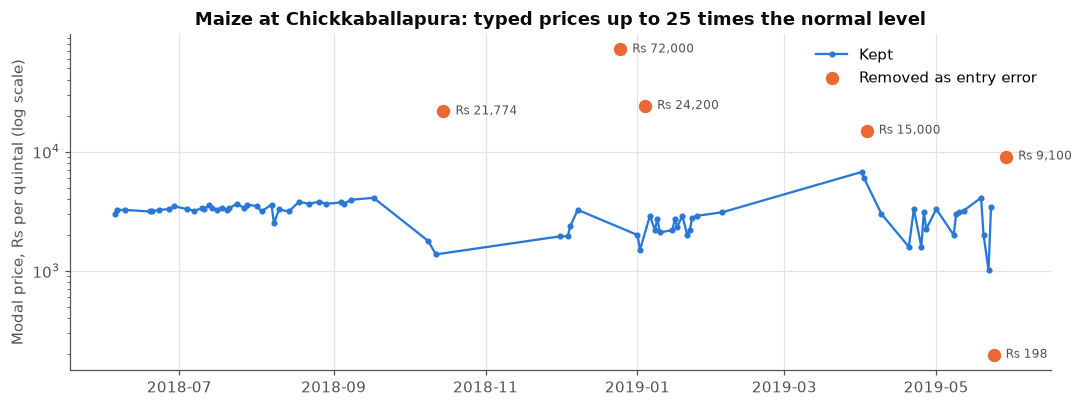

In [11]:
ex = df[(df["commodity"] == "Maize") & (df["market"] == "Chickkaballapura")
        & (df["date"].between("2018-06-01", "2019-06-30"))].sort_values("date")
fig, ax = plt.subplots(figsize=(10, 3.8))
ok = ex[~ex["out_entry_error"]]
ax.plot(ok["date"], ok["modal_price"], color=BLUE, linewidth=1.5, marker="o", markersize=3, label="Kept")
bad = ex[ex["out_entry_error"]]
ax.scatter(bad["date"], bad["modal_price"], color=ORANGE, s=60, zorder=3, label="Removed as entry error")
for _, r in bad.iterrows():
    ax.annotate(f"Rs {r.modal_price:,.0f}", (r.date, r.modal_price), textcoords="offset points", xytext=(8, -2), fontsize=8, color=MUTED)
ax.set_yscale("log")
ax.set_ylabel("Modal price, Rs per quintal (log scale)")
ax.set_title("Maize at Chickkaballapura: typed prices up to 25 times the normal level")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Example: a real spike that must be kept.** Onion prices across Karnataka in 2019-2020. Every market rose together
during the national onion shortage of late 2019, so the entry-error rule leaves the high prices alone, while the global
IQR rule would have deleted most of them. The few records the rule does catch in this period are the opposite case:
**very low** prices (one market reporting Rs 500-1,000 while the rest of the state was at Rs 4,500-6,500).

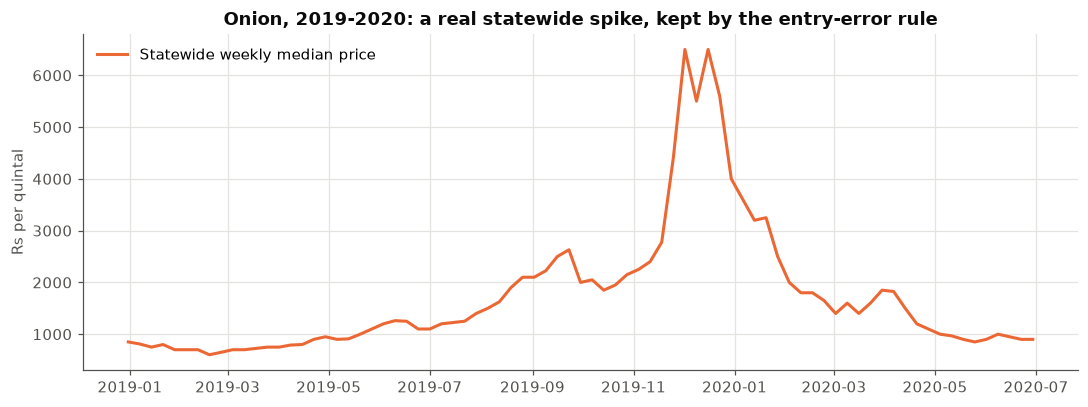

Onion records Nov-Dec 2019: 760
  flagged by global IQR:      503
  flagged by entry-error rule: 19  (above the statewide median: 0, below it: 19)


In [12]:
on = df[(df["commodity"] == "Onion") & (df["date"].between("2019-01-01", "2020-06-30"))]
weekly_state = on.groupby("week")["modal_price"].median()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(weekly_state.index, weekly_state.values, color=ORANGE, linewidth=2, label="Statewide weekly median price")
ax.set_ylabel("Rs per quintal")
ax.set_title("Onion, 2019-2020: a real statewide spike, kept by the entry-error rule")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

spike = on[on["date"].between("2019-11-01", "2019-12-31")]
print(f"Onion records Nov-Dec 2019: {len(spike):,}")
print(f"  flagged by global IQR:      {spike['out_iqr'].sum():,}")
print(f"  flagged by entry-error rule: {spike['out_entry_error'].sum():,}"
      f"  (above the statewide median: {(spike['out_entry_error'] & (spike['state_ratio'] > 1)).sum()},"
      f" below it: {(spike['out_entry_error'] & (spike['state_ratio'] < 1)).sum()})")

**Treatment.**
- **Entry errors** are removed (their price is unknown, so the record is dropped; the gap it leaves is handled with
  the other missing values in Step 7).
- **Robust z outliers that are not entry errors** are kept and flagged (`flag_extreme`). They are unusual but plausible
  and could matter to a farmer. Models in later notebooks can be compared with and without them.

[6a Outliers] Removed entry errors (far from own market AND from statewide price): 329 rows affected -> 253,833 rows
[6b Outliers] Flagged extreme-but-plausible prices (kept): 7,298 rows affected -> 253,833 rows
[6c Outliers] Flagged market-years priced 2x above or below the state (kept): 1,331 rows affected -> 253,833 rows


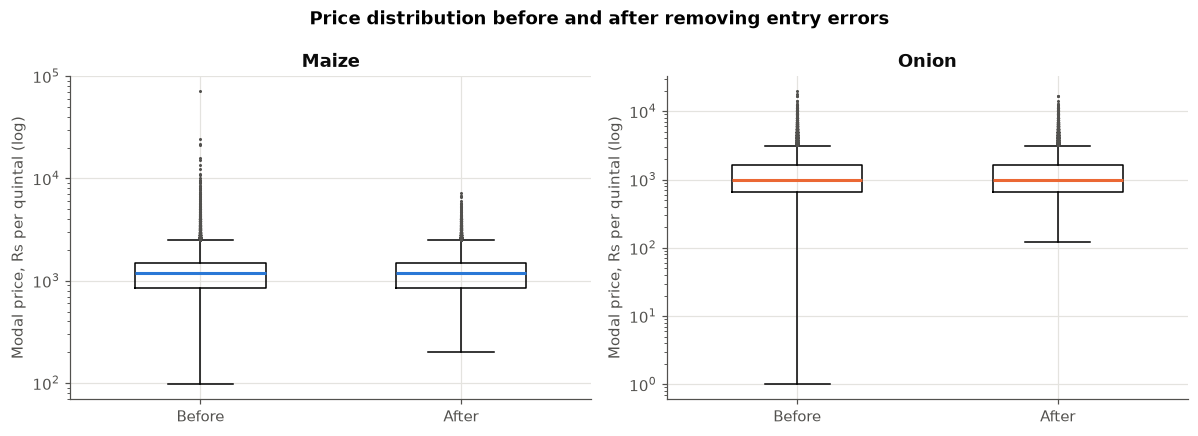

count    mean    std    min     1%     50%     99%      max
       commodity                                                                
before Maize      163942.0  1238.0  560.0   97.0  450.0  1200.0  2509.0  72000.0
       Onion       90220.0  1289.0  975.0    1.0  250.0  1000.0  4800.0  20000.0
after  Maize      163822.0  1234.0  509.0  200.0  450.0  1200.0  2500.0   7280.0
       Onion       90011.0  1286.0  960.0  120.0  250.0  1000.0  4800.0  17000.0

In [13]:
before_df = df.copy()   # snapshot for the before/after comparison
before = len(df)
df = df[~df["out_entry_error"]].copy()
record("6a Outliers", "Removed entry errors (far from own market AND from statewide price)", before - len(df), len(df))
df["flag_extreme"] = df["out_robust_z"] & ~df["out_entry_error"]
record("6b Outliers", "Flagged extreme-but-plausible prices (kept)", df["flag_extreme"].sum(), len(df))

# Some markets sit far above or below the state for a whole year (a different local product, or a retail-style market).
# That is a level difference, not a typing error, so these records are kept and flagged; later models use per-market features.
my_med = df.groupby(["commodity", "market", "year"])["modal_price"].transform("median")
sy_med = df.groupby(["commodity", "year"])["modal_price"].transform("median")
df["flag_odd_market_year"] = (my_med / sy_med >= 2) | (my_med / sy_med <= 0.5)
record("6c Outliers", "Flagged market-years priced 2x above or below the state (kept)", df["flag_odd_market_year"].sum(), len(df))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, crop in zip(axes, ["Maize", "Onion"]):
    b = before_df.loc[before_df["commodity"] == crop, "modal_price"]
    a = df.loc[df["commodity"] == crop, "modal_price"]
    ax.boxplot([b, a], tick_labels=["Before", "After"], widths=0.5, showfliers=True,
               flierprops=dict(marker=".", markersize=2, markerfacecolor=MUTED, markeredgecolor=MUTED),
               medianprops=dict(color=CROP_COLOR[crop], linewidth=2))
    ax.set_yscale("log"); ax.set_title(crop); ax.set_ylabel("Modal price, Rs per quintal (log)")
fig.suptitle("Price distribution before and after removing entry errors", fontweight="bold")
plt.tight_layout(); plt.show()

compare = pd.concat({
    "before": before_df.groupby("commodity")["modal_price"].describe(percentiles=[.01, .5, .99]),
    "after": df.groupby("commodity")["modal_price"].describe(percentiles=[.01, .5, .99])}).round(0)
compare

## 7. Missing values

### 7.1 Diagnose the pattern

Mandis do not report every day: a market that sold no onion that day sends nothing. Daily data is therefore mostly
gaps. The analysis works at **weekly** level (median price per market per week), which keeps the information a
farmer needs and removes most day-to-day gaps.

The weekly panel uses **2010 onwards** (Notebook 1 showed far fewer records before 2010) and **core markets**:
markets that report in at least half of all weeks. Other markets stay in the cleaned record file for EDA.

In [14]:
PANEL_START, PANEL_END = "2010-01-04", df["date"].max()
weeks = pd.date_range(PANEL_START, PANEL_END, freq="W-MON")
p = df[df["date"] >= PANEL_START]

weekly = (p.groupby(["commodity", "market", "week"])
            .agg(price=("modal_price", "median"), n_reports=("modal_price", "size"),
                 district=("district", "first"))
            .reset_index())
coverage = weekly.groupby(["commodity", "market"]).size() / len(weeks)
core = coverage[coverage >= 0.5].reset_index()[["commodity", "market"]]
print("Core markets (report in >= 50% of weeks):")
print(core.groupby("commodity").size())

# full grid: every core market x every week, so missing weeks become visible as NaN
grid = core.merge(pd.DataFrame({"week": weeks}), how="cross")
panel = grid.merge(weekly, on=["commodity", "market", "week"], how="left")
panel["district"] = panel.groupby(["commodity", "market"])["district"].transform(lambda s: s.ffill().bfill())
panel["n_reports"] = panel["n_reports"].fillna(0).astype(int)
print(f"\nPanel cells: {len(panel):,} | missing weeks: {panel['price'].isna().sum():,} "
      f"({panel['price'].isna().mean()*100:.1f}%)")

Core markets (report in >= 50% of weeks):
commodity
Maize    48
Onion    18
dtype: int64

Panel cells: 56,100 | missing weeks: 16,064 (28.6%)


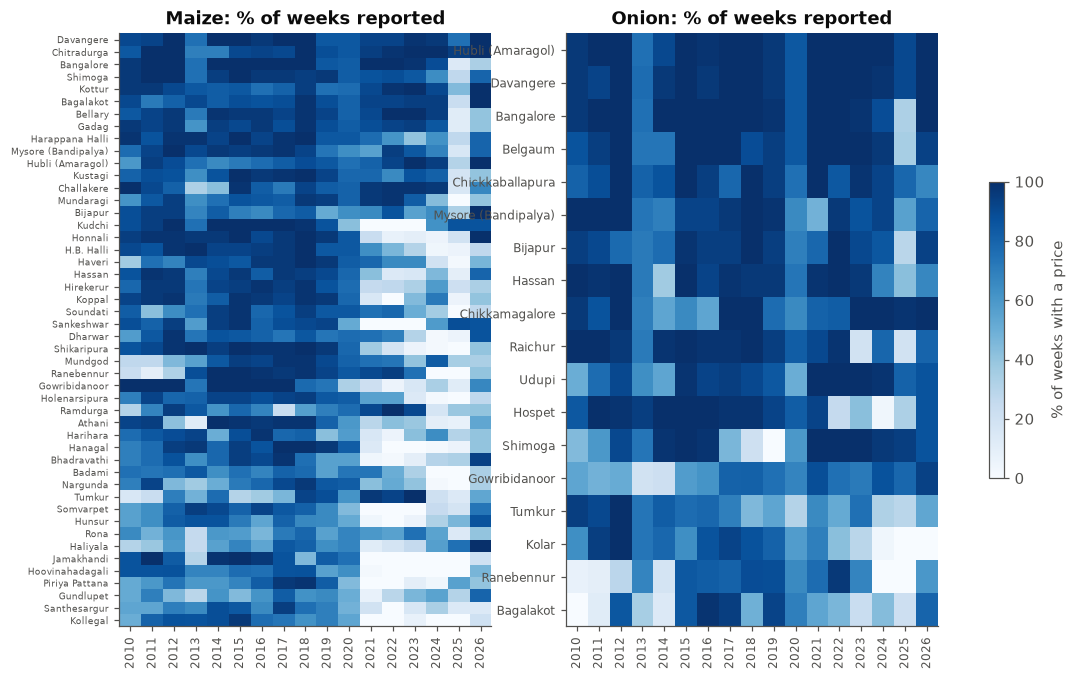

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), gridspec_kw={"width_ratios": [47, 47]})
for ax, crop in zip(axes, ["Maize", "Onion"]):
    m = panel[panel["commodity"] == crop].assign(year=lambda x: x["week"].dt.year)
    heat = m.groupby(["market", "year"])["price"].apply(lambda s: s.notna().mean() * 100).unstack()
    heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
    im = ax.imshow(heat.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
    ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index, fontsize=6 if crop == "Maize" else 8)
    ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=90, fontsize=8)
    ax.grid(False); ax.set_title(f"{crop}: % of weeks reported")
fig.colorbar(im, ax=axes, shrink=0.5, label="% of weeks with a price")
plt.show()

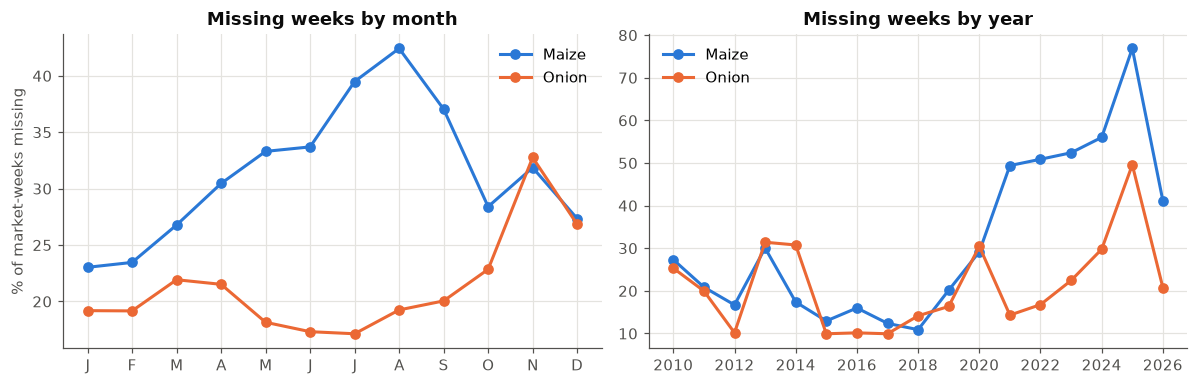

Gap length in weeks:
count    3780.0
mean        4.2
std        12.9
min         1.0
50%         1.0
75%         3.0
90%         8.0
95%        12.0
max       280.0
dtype: float64
Share of gaps that are 8 weeks or shorter: 91.0%


In [16]:
# Is missingness random, or does it follow the season and specific years?
panel["month"] = panel["week"].dt.month
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for crop in ["Maize", "Onion"]:
    m = panel[panel["commodity"] == crop]
    axes[0].plot(range(1, 13), m.groupby("month")["price"].apply(lambda s: s.isna().mean() * 100),
                 color=CROP_COLOR[crop], marker="o", linewidth=2, label=crop)
    axes[1].plot(m.groupby(m["week"].dt.year)["price"].apply(lambda s: s.isna().mean() * 100),
                 color=CROP_COLOR[crop], marker="o", linewidth=2, label=crop)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(list("JFMAMJJASOND"))
axes[0].set_title("Missing weeks by month"); axes[0].set_ylabel("% of market-weeks missing")
axes[1].set_title("Missing weeks by year")
for ax in axes: ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# How long are the gaps?
def gap_lengths(s):
    isna = s.isna().values
    out, run = [], 0
    for v in isna:
        if v: run += 1
        elif run: out.append(run); run = 0
    if run: out.append(run)
    return out
gaps = pd.Series([g for _, s in panel.sort_values("week").groupby(["commodity", "market"])["price"] for g in gap_lengths(s)])
print("Gap length in weeks:")
print(gaps.describe(percentiles=[.5, .75, .9, .95]).round(1))
print(f"Share of gaps that are 8 weeks or shorter: {(gaps <= 8).mean()*100:.1f}%")

**What the pattern shows.** Missing weeks are **not random**: they cluster in particular months (when a crop is
off-season in some markets) and particular years (for example the empty November-December 2020 in the source files).
This matters: deleting missing weeks would drop whole seasons, and a filling method must use the crop's own
seasonal and statewide pattern rather than a single overall average.

### 7.2 Compare filling methods

Known prices are hidden on purpose, filled back in by each method, and compared with the true value. Two tests:
- **Random**: hide 10% of known weeks at random.
- **Gap**: hide random 4-week blocks, which is closer to real gaps.

Methods compared:

| Method | How it fills a missing week |
| --- | --- |
| Deletion | does not fill; the week is dropped (cost shown as data lost) |
| Market median | the market's overall median price |
| Market x month median (group-based) | the market's median price for that calendar month |
| Forward fill | the last known price in that market (uses only the past) |
| Linear interpolation | a straight line between the known weeks before and after |
| Statewide-ratio (neighbour-based) | that week's statewide median x the market's usual ratio to the statewide median |

In [17]:
rng = np.random.default_rng(SEED)
panel = panel.sort_values(["commodity", "market", "week"]).reset_index(drop=True)
panel["state_median"] = panel.groupby(["commodity", "week"])["price"].transform("median")

def fill_methods(s_panel):
    """Return a DataFrame of filled values from each method for a panel where some prices are NaN."""
    out = pd.DataFrame(index=s_panel.index)
    g = s_panel.groupby(["commodity", "market"])["price"]
    out["Market median"] = g.transform("median")
    out["Market x month median"] = s_panel.groupby(["commodity", "market", "month"])["price"].transform("median")
    out["Forward fill"] = g.ffill()
    out["Linear interpolation"] = g.transform(lambda s: s.interpolate(limit_area="inside"))
    state = s_panel.groupby(["commodity", "week"])["price"].transform("median")
    ratio = (s_panel["price"] / state).groupby([s_panel["commodity"], s_panel["market"]]).transform("median")
    out["Statewide ratio"] = state * ratio
    return out

def evaluate(mask, label):
    test = panel.copy()
    truth = test.loc[mask, "price"]
    test.loc[mask, "price"] = np.nan
    filled = fill_methods(test)
    rows = []
    for m in filled.columns:
        est = filled.loc[mask, m]
        ok = est.notna()
        for crop in ["Maize", "Onion"]:
            c = ok & (test.loc[mask, "commodity"] == crop)
            err = (est[c] - truth[c]).abs()
            rows.append({"test": label, "method": m, "crop": crop,
                         "MAE (Rs)": err.mean(), "MAPE (%)": (err / truth[c]).mean() * 100,
                         "filled (%)": c.sum() / (test.loc[mask, "commodity"] == crop).sum() * 100})
    return pd.DataFrame(rows)

known = panel["price"].notna()
random_mask = known & (rng.random(len(panel)) < 0.10)

block_mask = pd.Series(False, index=panel.index)
for (_, _), idx in panel.groupby(["commodity", "market"]).groups.items():
    idx = np.array(idx)
    for start in rng.choice(len(idx) - 4, size=max(1, len(idx) // 40), replace=False):
        block_mask.iloc[idx[start:start + 4]] = True
block_mask &= known

results = pd.concat([evaluate(random_mask, "Random 10%"), evaluate(block_mask, "4-week gaps")])
summary = results.pivot_table(index="method", columns=["test", "crop"], values="MAPE (%)").round(1)
summary["average"] = summary.mean(axis=1).round(1)
summary = summary.sort_values("average")
print(f"Hidden values: random test {random_mask.sum():,}, gap test {block_mask.sum():,}")
print("Mean absolute percentage error (MAPE) of each filling method, lower is better:")
summary

Hidden values: random test 3,961, gap test 3,799
Mean absolute percentage error (MAPE) of each filling method, lower is better:


test                  4-week gaps       Random 10%       average
crop                        Maize Onion      Maize Onion        
method                                                          
Linear interpolation          4.4  14.6        3.6  10.1     8.2
Forward fill                  5.7  21.4        4.6  13.0    11.2
Statewide ratio               5.6  17.0        5.6  17.1    11.3
Market median                22.2  46.7       21.9  41.6    33.1
Market x month median        23.2  48.6       22.1  42.0    34.0

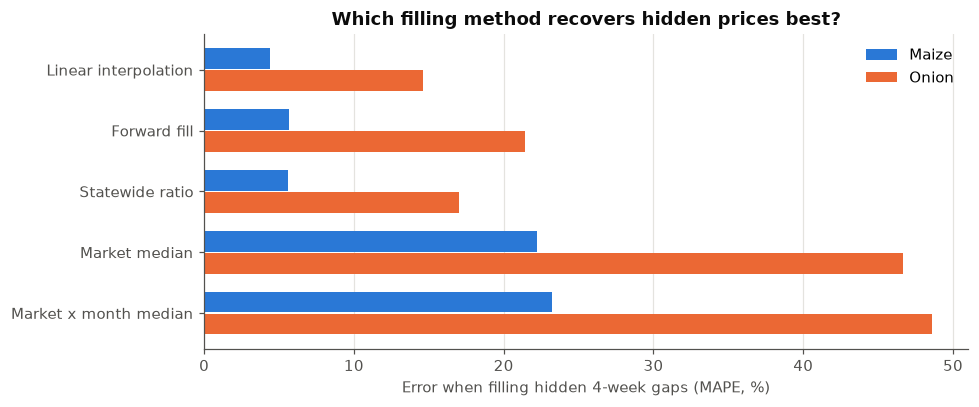

Deletion instead of filling would remove these shares of market-weeks:
commodity
Maize    31.4%
Onion    21.3%
Name: price, dtype: str


In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = summary.index.tolist()
y = np.arange(len(order))
for i, (crop, color) in enumerate([("Maize", BLUE), ("Onion", ORANGE)]):
    vals = results[(results["test"] == "4-week gaps") & (results["crop"] == crop)].set_index("method").loc[order, "MAPE (%)"]
    ax.barh(y + (i - 0.5) * 0.36, vals, height=0.34, color=color, label=crop)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("Error when filling hidden 4-week gaps (MAPE, %)")
ax.set_title("Which filling method recovers hidden prices best?")
ax.grid(axis="y", visible=False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

deleted = panel["price"].isna().groupby(panel["commodity"]).mean() * 100
print("Deletion instead of filling would remove these shares of market-weeks:")
print(deleted.round(1).astype(str) + "%")

### 7.3 Apply the best method

The method with the lowest average error is applied, but **only to gaps of 8 weeks or less**. Longer gaps are left
empty: inventing two or more months of prices would be guessing, not filling. Every filled value is flagged
(`was_imputed`), so later notebooks can check results with and without them.

*Leakage note for the viva:* interpolation and statewide-ratio filling use information from after the missing week.
That is fine for describing the past (EDA), but a forecasting model must not see the future. The modelling notebook
therefore builds its features from **past values only**, and the imputed flag lets it exclude filled weeks from the
test period.

In [19]:
best = summary.index[0]
print("Best method:", best)
MAX_GAP = 8

filled = fill_methods(panel)[best]

# gap length for every missing cell, so only short gaps are filled
def run_lengths(s):
    isna = s.isna()
    grp_id = (~isna).cumsum()
    return isna.groupby(grp_id).transform("sum").where(isna, 0)
panel["gap_len"] = panel.groupby(["commodity", "market"])["price"].transform(run_lengths)

fill_here = panel["price"].isna() & (panel["gap_len"] <= MAX_GAP) & filled.notna()
panel["price_filled"] = panel["price"].where(~fill_here, filled)
panel["was_imputed"] = fill_here
record("7 Missing", f"Filled weekly gaps of <= {MAX_GAP} weeks using '{best}'", fill_here.sum(), len(panel))

summary_missing = panel.groupby("commodity").agg(
    market_weeks=("price", "size"),
    missing_before=("price", lambda s: s.isna().sum()),
    filled=("was_imputed", "sum"),
    missing_after=("price_filled", lambda s: s.isna().sum()))
summary_missing["missing_after_%"] = (summary_missing["missing_after"] / summary_missing["market_weeks"] * 100).round(1)
summary_missing

Best method: Linear interpolation
[7 Missing] Filled weekly gaps of <= 8 weeks using 'Linear interpolation': 6,738 rows affected -> 56,100 rows


,market_weeks,missing_before,filled,missing_after,missing_after_%
commodity,,,,,
Maize,40800,12802,5217,7585,18.6
Onion,15300,3262,1521,1741,11.4


## 8. Before/after summary and save

In [20]:
clean = df.drop(columns=["ym", "rel_price", "year", "robust_z", "own_ratio", "state_ratio",
                         "out_iqr", "out_robust_z", "out_entry_error"])
clean = clean.sort_values(["commodity", "market", "date"]).reset_index(drop=True)

checks = pd.DataFrame({
    "Raw file": {
        "Records": len(raw),
        "Modal price <= 0 or missing": int((raw["Modal_Price"] <= 0).sum() + raw["Modal_Price"].isna().sum()),
        "Min or max price <= 0": int(((raw["Min_Price"] <= 0) | (raw["Max_Price"] <= 0)).sum()),
        "Min above max": int((raw["Min_Price"] > raw["Max_Price"]).sum()),
        "Duplicate market-variety-grade-date": int(raw.duplicated(["Market", "Commodity", "Variety", "Grade", "Arrival_Date"]).sum()),
        "Varieties": raw.groupby("Commodity")["Variety"].nunique().sum(),
        "Grade labels": raw["Grade"].nunique(),
        "Market names": raw["Market"].nunique(),
        "Records with ' APMC' in market name": int(raw["Market"].str.contains(r"\s+APMC$", regex=True).sum()),
    },
    "Cleaned file": {
        "Records": len(clean),
        "Modal price <= 0 or missing": int((clean["modal_price"] <= 0).sum() + clean["modal_price"].isna().sum()),
        "Min or max price <= 0": int(((clean["min_price"] <= 0) | (clean["max_price"] <= 0)).sum()),
        "Min above max": int((clean["min_price"] > clean["max_price"]).sum()),
        "Duplicate market-variety-grade-date": int(clean.duplicated(["market", "commodity", "variety", "grade", "date"]).sum()),
        "Varieties": clean.groupby("commodity")["variety"].nunique().sum(),
        "Grade labels": clean["grade"].nunique(),
        "Market names": clean["market"].nunique(),
        "Records with ' APMC' in market name": int(clean["market"].str.contains(r"\s+APMC$", regex=True).sum()),
    }})
checks

,Raw file,Cleaned file
Records,267369,253833
Modal price <= 0 or missing,0,0
Min or max price <= 0,693,0
Min above max,12,0
Duplicate market-variety-grade-date,7,0
Varieties,24,15
Grade labels,9,4
Market names,253,149
Records with ' APMC' in market name,5055,0


In [21]:
clean.to_csv("../data/focus_crops_clean.csv", index=False)
panel_out = panel[["commodity", "market", "district", "week", "n_reports", "price", "price_filled",
                   "was_imputed", "state_median"]]
panel_out.to_csv("../data/weekly_panel.csv", index=False)
log_df = pd.DataFrame(log)
log_df.to_csv("../data/cleaning_log.csv", index=False)

print(f"Saved data/focus_crops_clean.csv: {len(clean):,} records")
print(f"Saved data/weekly_panel.csv: {len(panel_out):,} market-weeks "
      f"({panel_out['market'].nunique()} markets, {panel_out['week'].min().date()} to {panel_out['week'].max().date()})")
print("Saved data/cleaning_log.csv")
log_df

Saved data/focus_crops_clean.csv: 253,833 records
Saved data/weekly_panel.csv: 56,100 market-weeks (55 markets, 2010-01-04 to 2026-04-13)
Saved data/cleaning_log.csv


,step,detail,rows_affected,rows_after
0,1 Types,"Converted text, dates and prices to proper types",0,267369
1,1b Names,Removed ' APMC' suffix added to market names f...,5055,267369
2,2 Period,Dropped records before 2003 (too sparse),7228,260141
3,3a Validate,Dropped records with modal price missing or <= 0,0,260141
4,3b Validate,min_price <= 0 set to missing (modal kept),677,260141
5,3b Validate,max_price <= 0 set to missing (modal kept),524,260141
6,3c Validate,Swapped min and max where min > max,0,260141
7,3d Validate,Flagged modal price outside min-max range (kept),7,260141
8,4a Duplicates,Dropped exact duplicate records,39,260102
9,4b Duplicates,Merged conflicting records into one (median pr...,7,260095


## What to say about cleaning in the report

- Every step is rule-based and counted in `cleaning_log.csv`, so the whole cleaning can be rerun from the raw file.
- The modal price is the analysed variable, so records were dropped only when it was unusable; bad minimum or
  maximum prices were set to missing instead.
- Outliers were treated by **cause**, not by size: the textbook IQR rule would have deleted real price crises; the
  entry-error rule removes only prices that disagree with both their own market and the rest of Karnataka.
- Missing data was **diagnosed before it was filled**: it is seasonal, not random. Five filling methods were tested on
  deliberately hidden prices; the best was applied only to gaps of up to 8 weeks, and every filled value is flagged.
- Scaling and encoding are left to the modelling notebook to avoid data leakage.